In [221]:
## Basics setup
import numpy as np
from numpy import random
import matplotlib.pyplot as plt
import copy
from statistics import mean
import math
import ollama
LANDSCAPE_LENGTH = 100
NUM_AGENTS = 100
MAX_STEP = 20 #40 #upped for double gaussian
HEURISTIC_LENGTH = 3
TEAM_SIZE = 4
VERBOSE = False 
N_RERUNS = 100

# options for strategies: 
# Note:  "duplicates" here is not about agents but about elements within the heuristic
        # "NoRepeatsSorted": list of HEURISTIC_LENGTH elements where each element is random choice between 1 and max_step
        # "AllowRepeatsUnsorted": list of HEURISTIC_LENGTH elements where each element is random choice between 1 and max_step, repeats allowed, not sorted
        # "NoRepeatsUnsorted": list of HEURISTIC_LENGTH elements where each element is random choice between 1 and max_step, repeats not allowed, not sorted
STRATEGY_TYPE = "NoRepeatsUnsorted"
START_STRATEGY = "Beginning"

LANDSCAPE_TYPE = "Gaussian"

In [ ]:
## Seed the landscape, create agent dictionary, specify starting positions
random.seed(43)
def landscape_seeder(i):
    if LANDSCAPE_TYPE == "Gaussian":
        return int(100 * math.exp(-((i - LANDSCAPE_LENGTH / 2) ** 2) / (2 * (LANDSCAPE_LENGTH / 5) ** 2)))
    elif LANDSCAPE_TYPE == "DoubleGaussian":
        return int(100 * (math.exp(-((i - LANDSCAPE_LENGTH * 0.3) ** 2) / (2 * (LANDSCAPE_LENGTH / 10) ** 2)) + math.exp(-((i - LANDSCAPE_LENGTH * 0.7) ** 2) / (2 * (LANDSCAPE_LENGTH / 10) ** 2))))
    elif LANDSCAPE_TYPE == "Random":
        return random.randint(0, 100)

LANDSCAPE = [{"location": i, "value": landscape_seeder(i)} for i in range(LANDSCAPE_LENGTH)]


AGENTS = [
    {"heuristic": [], "CurrentValue": [], "position": []}
    for _ in range(NUM_AGENTS)
]
for agent in AGENTS:
    
    if STRATEGY_TYPE == "AllowRepeatsUnsorted": 
        heuristic = random.choice(range(1, MAX_STEP+1), HEURISTIC_LENGTH)
        agent["heuristic"] = heuristic.tolist()

    elif STRATEGY_TYPE == "NoRepeatsUnsorted":
            heuristic = random.choice(range(1, MAX_STEP+1), HEURISTIC_LENGTH, replace=False)
            agent["heuristic"] = heuristic.tolist()

    elif STRATEGY_TYPE == "NoRepeatsSorted":
        heuristic = random.choice(range(1, MAX_STEP+1), HEURISTIC_LENGTH, replace=False)
        agent["heuristic"] = sorted(heuristic.tolist())

    
    if START_STRATEGY == "Random":
        agent["position"] = random.randint(0, LANDSCAPE_LENGTH-1)
    elif START_STRATEGY == "Beginning":
        agent["position"] = 0
        
    agent["CurrentValue"] = LANDSCAPE[agent["position"]]["value"]

if VERBOSE: 
    print(LANDSCAPE)
    print(AGENTS)


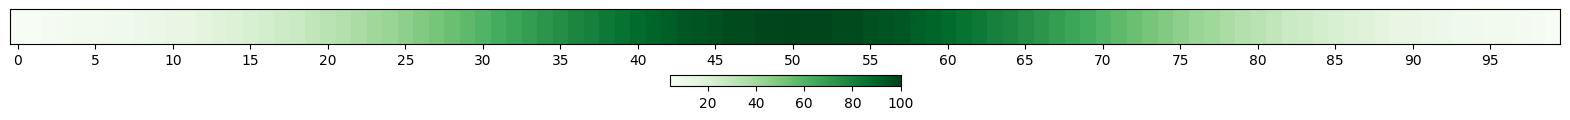

In [207]:
## Plot the landscape

def strip_heatmap(LANDSCAPE, cmap="Greens", labels=False, figsize=(20, 1)):
    values = np.asarray([location["value"] for location in LANDSCAPE])
    fig, ax = plt.subplots(figsize=figsize)
    ax.get_yaxis().set_visible(False)
    ax.set_xticks(np.arange(0, len(values), 5))
    im = ax.imshow(values[np.newaxis, :], cmap=cmap, aspect="auto")
    fig.colorbar(im, ax=ax, orientation="horizontal", pad=0.4)
    plt.show()
strip_heatmap(LANDSCAPE)

In [202]:
def climb(agent):
    """Move until a full pass finds nothing better. Returns (final_pos, value of position).
    Note: agent checks heuristic from where they left off, not fresh."""
    n = len(agent["heuristic"])
    i = 0         # which heuristic element to try next
    misses = 0    # consecutive checks with no improvement

    while misses < n:
        candidate = (agent["position"] + agent["heuristic"][i]) % LANDSCAPE_LENGTH
        if LANDSCAPE[candidate]["value"] > LANDSCAPE[agent["position"]]["value"]:
            misses = 0
            if VERBOSE:
                print("Moving from", agent["position"], "with value", LANDSCAPE[agent["position"]]["value"],
                       "to", candidate, "with value", LANDSCAPE[candidate]["value"])
            agent["position"] = candidate
            agent["CurrentValue"] = LANDSCAPE[candidate]["value"]

        else:
            misses += 1

        i = (i + 1) % n

    return agent

In [204]:
agents = copy.deepcopy(AGENTS)
for agent in agents:
       agent = climb(agent)

agents_sorted = sorted(agents,key=lambda a: a["CurrentValue"], reverse=True)
for rank, agent in enumerate(agents_sorted[:10], start=1):
    print("Agent", agent["heuristic"], "had current value", agent["CurrentValue"], "at location", agent["position"])

Agent [5, 2, 14] had current value 100 at location 30
Agent [1, 10, 18] had current value 100 at location 30
Agent [1, 11, 18] had current value 100 at location 30
Agent [16, 14, 17] had current value 100 at location 30
Agent [4, 8, 2] had current value 100 at location 30
Agent [9, 2, 3] had current value 100 at location 30
Agent [16, 14, 4] had current value 100 at location 30
Agent [2, 4, 1] had current value 100 at location 30
Agent [8, 14, 4] had current value 100 at location 30
Agent [11, 19, 18] had current value 100 at location 30


In [ ]:
response = ollama.generate(
    model='llama3.1:8b', 
    prompt = f"""You are an agent trying to find the maximum value in a list of {LANDSCAPE_LENGTH} elements. The list has {LANDSCAPE_TYPE} feature. You can move only forward and the list loops around when you get to the end. I want you to develop a strategy called a heuristic. Your heuristic consists of the steps forward you want to take. It can only be {HEURISTIC_LENGTH} elements long, cannot include duplicates, and can have your elements in any order. The maximum steps forward you can take (the maximum element you can have in your heuristic) is {MAX_STEP}. You will begin by checking the value of the location (your starting location plus the first element of your heuristic). If that is better than your current location, you will move there and check (that location plus your second heuristic). If not, check your starting location plus second heuristic. Repeat until you have exhausted your list of heuristics and cannot find a better location to move to. What is your heuristic?"""
)

print(response['response'])


What a delightful problem!

Given the Gaussian distribution of the list, I'll develop a heuristic that takes into account the expected behavior of the distribution. Since the list loops around, I'll focus on finding a heuristic that balances the probability of finding a better location and the number of steps taken.

My heuristic will consist of three steps, with no duplicates, and the maximum step size will be 20. Here's my chosen heuristic:

Heuristic: [3, 7, 10]

Here's my reasoning:

1. **Start with a relatively small step**: The first step of 3 allows me to quickly explore the nearby locations and get a sense of the distribution's behavior.
2. **Jump to a larger step**: The second step of 7 is significantly larger than the first step, which will help me move further into the list and explore more of the distribution. This step is large enough to cover a good portion of the list, but not so large that I'll waste too many steps.
3. **Take a moderate step**: The third step of 10 is s

In [220]:
LLMagents = [
    {"heuristic": [5, 3, 10], "CurrentValue": [], "position": []}
]
for llmagent in LLMagents:
    if START_STRATEGY == "Random":
        llmagent["position"] = random.randint(0, LANDSCAPE_LENGTH-1)
    elif START_STRATEGY == "Beginning":
        llmagent["position"] = 0
    llmagent["CurrentValue"] = LANDSCAPE[llmagent["position"]]["value"]

for llmagent in LLMagents:
    climb(llmagent)

llmagents_sorted = sorted(LLMagents,key=lambda a: a["CurrentValue"], reverse=True)
for rank, llmagent in enumerate(llmagents_sorted[:10], start=1):
    print("Agent", llmagent["heuristic"], "had current value", llmagent["CurrentValue"], "at location", llmagent["position"])

Agent [5, 3, 10] had current value 98 at location 54


In [222]:
response = ollama.generate(
    model='llama3.1:8b', 
    prompt = f"""You have a team of {TEAM_SIZE} trying to find the maximum value in a list of {LANDSCAPE_LENGTH} elements. The list has {LANDSCAPE_TYPE} feature. You can move only forward and the list loops around when you get to the end. I want each member of your team to develop a strategy called a heuristic. EACH heuristic consists of the steps forward you want to take. It can only be {HEURISTIC_LENGTH} elements long, cannot include duplicates, and can have your elements in any order. The maximum steps forward you can take (the maximum element you can have in your heuristic) is {MAX_STEP}. You will begin by checking the value of the location (your starting location plus the first element of your heuristic). If that is better than your current location, you will move there and check (that location plus your second heuristic). If not, check your starting location plus second heuristic. Repeat until you have exhausted your list of heuristics and cannot find a better location to move to. What are your team's heuristics?"""
)

print(response['response'])


After some deliberation, each member of the team has come up with their own unique heuristic strategy. Here they are:

**Team Member 1: "The Conservative"**
Heuristic: [3, 5, 7]

This team member is cautious and wants to explore the list carefully. By taking small steps forward, they aim to minimize the risk of missing a better location.

**Team Member 2: "The Optimist"**
Heuristic: [10, 15, 20]

This team member is confident that the maximum value is likely to be at the end of the list. By taking larger steps forward, they hope to quickly find the best location.

**Team Member 3: "The Explorer"**
Heuristic: [1, 3, 5]

This team member is adventurous and wants to explore as much of the list as possible. By taking short steps forward, they aim to cover a wide area and potentially stumble upon the maximum value.

**Team Member 4: "The Statistician"**
Heuristic: [5, 10, 15]

This team member has a statistical background and wants to balance exploration with a sense of "neighborhood" aware